<a href="https://colab.research.google.com/github/GauriRaut58/Gauri-/blob/main/Lab_5_ML_C_52_GAURI_RAUT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Name : Gauri Raut
#### Section : C(C4)
#### Roll No: 52
#### ML Lab - 5

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report,roc_curve,roc_auc_score
)

In [ ]:
df = pd.read_excel("diabetes.xlsx")
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (768, 9)


In [ ]:
print(df.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [ ]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


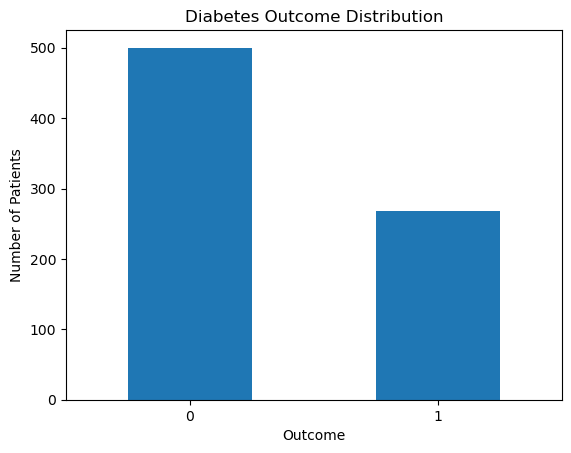

In [ ]:
df["Outcome"].value_counts().plot(kind="bar")

plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.title("Diabetes Outcome Distribution")
plt.xticks(rotation=0)

plt.show()

In [ ]:
columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [ ]:
correlation = df.corr(numeric_only=True)

print(correlation["Outcome"].sort_values(ascending=False))

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


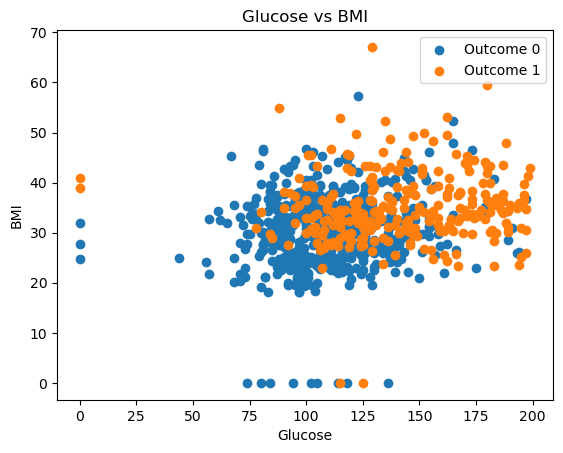

In [ ]:
for outcome in [0, 1]:

    data = df[df["Outcome"] == outcome]

    plt.scatter(
        data["Glucose"],
        data["BMI"],
        label=f"Outcome {outcome}"
    )

plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.title("Glucose vs BMI")
plt.legend()

plt.show()

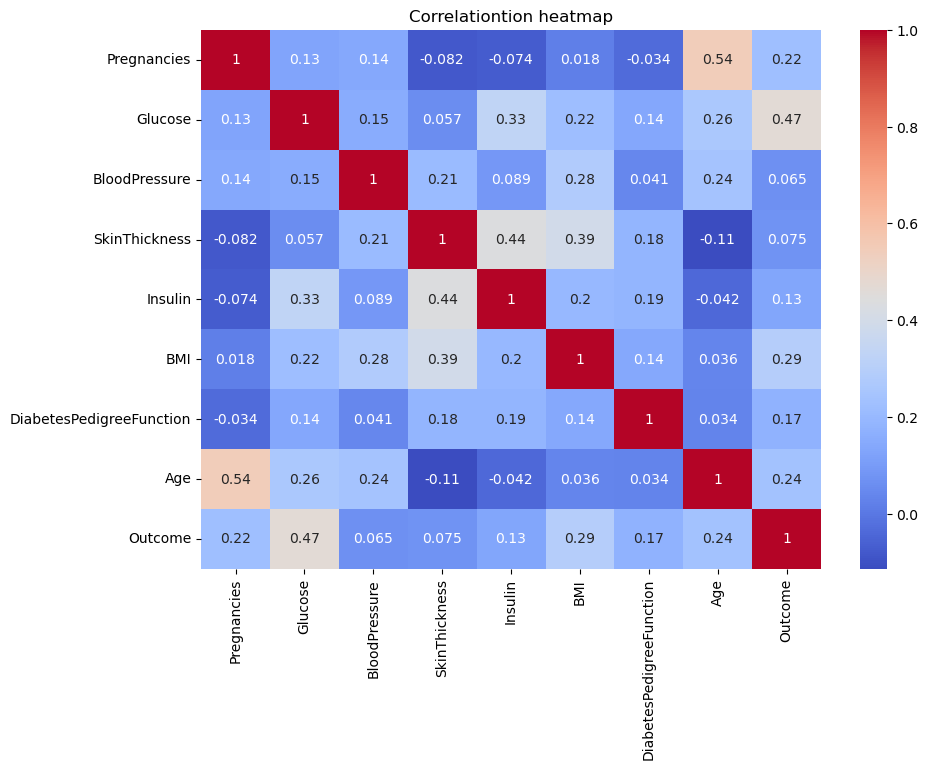

In [ ]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlationtion heatmap")
plt.show()

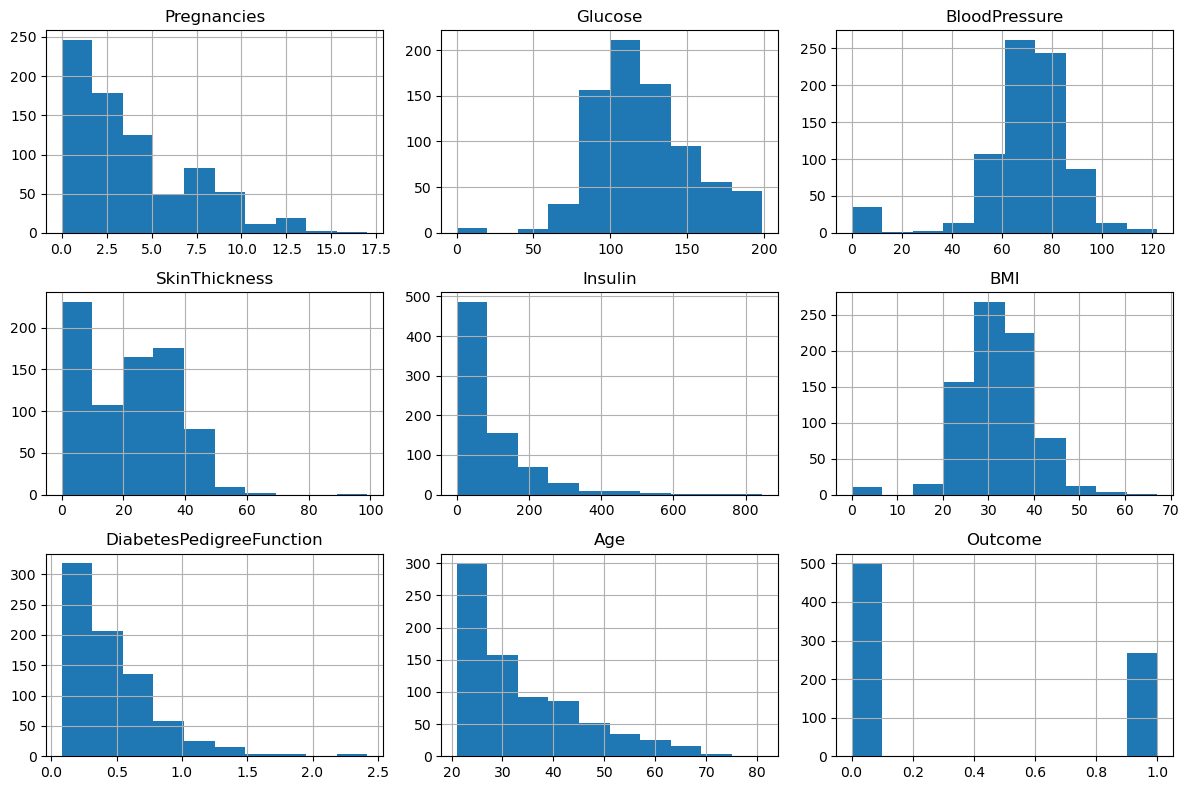

In [ ]:
# Distribution of Diabetes Dataset Features
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

In [ ]:
zero_columns = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = (df[zero_columns] == 0).sum()

print("Zero Values:")
print(zero_counts)

Zero Values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
df_clean = df.copy()

df_clean[zero_columns]=df_clean[zero_columns].replace(0,np.nan)

print("Missing values after replacing invalid zeros:")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    print("Missing values after median imputation")
    print(df_clean.isnull().sum())

Missing values after median imputation
Pregnancies                   0
Glucose                       0
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Missing values after median imputation
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Missing values after median imputation
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                  

In [ ]:
### Applying Algorithm
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]
print("X Shape:", X.shape)
print("y shpae:", y.shape)

X Shape: (768, 8)
y shpae: (768,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training Sample:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Sample: 614
Testing Samples: 154


In [ ]:
print("Traing Distribution")
print(y_train.value_counts(normalize=True))

print("\n testing Distribution")
print(y_test.value_counts(normalize=True))

Traing Distribution
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

 testing Distribution
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
scaler = standardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

NameError: name 'standardScaler' is not defined

In [ ]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
# 1. Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 2. Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 3. Standardization
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Compare Original vs Scaled data
comparison = pd.DataFrame({
    "Feature": X_train.columns,
    "Original Mean": X_train.mean().values,
    "Original std": X_train.std().values,
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled std": X_train_scaled.std(axis=0)
})

display(comparison)

,Feature,Original Mean,Original std,Scaled Mean,Scaled std
0,Pregnancies,3.742671,3.313264,1.735854e-17,1.0
1,Glucose,120.855049,32.035057,-2.169817e-17,1.0
2,BloodPressure,69.415309,18.512599,6.943414e-17,1.0
3,SkinThickness,20.399023,15.433974,1.041512e-16,1.0
4,Insulin,81.438111,116.234835,-2.603780e-17,1.0
5,BMI,31.983388,7.740625,-5.699386e-16,1.0
6,DiabetesPedigreeFunction,0.469168,0.336847,1.562268e-16,1.0
7,Age,32.907166,11.503437,-3.761016e-17,1.0


comparison = pd.DataFrame({
    "Feature": X.columns,
    "Original Mean": X_train.mean(axis=0),
    "Original std": X_train.std(axis=0),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled std": X_train_scaled.std(axis=0)
})

display(comparison)

In [ ]:
k =5


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [ ]:
y_pred = knn.predict_proba(X_test_scaled)[:, 1]

print("Probabilities:")
print(y_pred[:20])

Probabilities:
[0.2 0.2 0.  0.4 0.8 0.2 0.  0.6 0.8 0.4 0.4 0.4 0.2 0.4 0.  0.6 0.  0.
 0.8 0.2]


In [ ]:
y_prob = knn.predict_proba(X_test_scaled)[:, 1]
print(y_prob[:20])

[0.2 0.2 0.  0.4 0.8 0.2 0.  0.6 0.8 0.4 0.4 0.4 0.2 0.4 0.  0.6 0.  0.
 0.8 0.2]


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6948


In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")

Precision: 0.5833


In [ ]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print(f"Recall: {recall:.4f}")

Recall: 0.5091


In [ ]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print(f"F1 Score: {f1:.4f}")

F1 Score: 0.5437


In [ ]:
print(classification_report(y_test,y_pred,target_names=['No Diabetes','diabetes']))

              precision    recall  f1-score   support

 No Diabetes       0.75      0.80      0.77        99
    diabetes       0.58      0.51      0.54        55

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.66       154
weighted avg       0.69      0.69      0.69       154



In [ ]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[79 20]
 [27 28]]


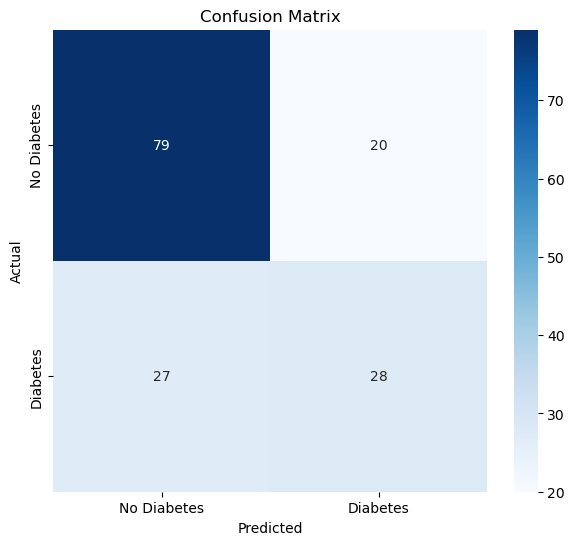

In [ ]:
plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
k_values = range(1,31)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors = k)
    model.fit(X_train_scaled,y_train)
    train_accuracy.append(model.score(X_train_scaled,y_train))
    test_accuracy.append(model.score(X_test_scaled,y_test))

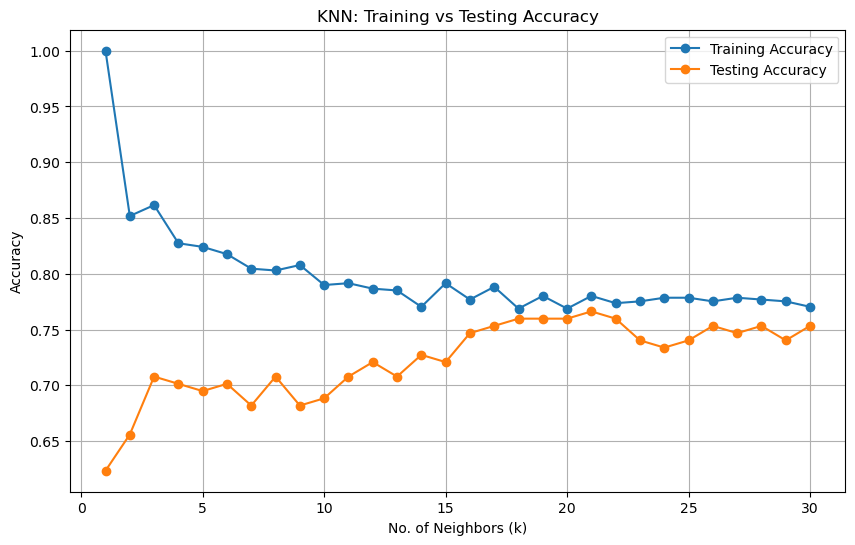

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(k_values, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(k_values, test_accuracy, marker="o", label="Testing Accuracy")

plt.xlabel("No. of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN: Training vs Testing Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)

print("Best k :", best_accuracy)
print("Best test Accuracy:", best_accuracy)

Best k : 0.7662337662337663
Best test Accuracy: 0.7662337662337663


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []

for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring="accuracy"
    )
    cv_scores.append(scores.mean())

print(cv_scores)

[0.7133679861388778, 0.7410635745701719, 0.7459016393442622, 0.7540450486472078, 0.749140343862455, 0.7459282953485273, 0.7671064907370384, 0.7475409836065574, 0.755684392909503, 0.7492069838731175, 0.757323737171798, 0.7573104091696654, 0.7573370651739304, 0.7491536718645875, 0.7426629348260696, 0.7377848860455818, 0.7345328535252565, 0.7459282953485273, 0.7508463281354125, 0.7459549513527921, 0.75083300013328, 0.7475409836065573, 0.7475809676129548, 0.7361455417832866, 0.7361322137811541, 0.7279488204718112, 0.7393709182993469, 0.7426496068239372, 0.7409969345595095, 0.7409969345595095]


In [ ]:
best_k = np.argmax(cv_scores) + 1

print("Best K based on cross validation:", best_k)
print("Best CV Accuracy:", max(cv_scores))

Best K based on cross validation: 7
Best CV Accuracy: 0.7671064907370384


In [ ]:
param_grid = {
    "n_neighbors": list(range(3, 31, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]
}

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Grid Search Completed")

Grid Search Completed


In [ ]:
print("Best parameters")
print(grid_search.best_params_)

Best parameters
{'metric': 'euclidean', 'n_neighbors': 11, 'p': 1, 'weights': 'distance'}


In [ ]:
print("Best Cross Validation Accuracy:", grid_search.best_score_)

Best Cross Validation Accuracy: 0.7655337864854058
